In [1]:
# Install Kaggle API
!pip install -q kaggle

# Install additional libraries if not already present
!pip install -q torch torchvision matplotlib


In [2]:
from google.colab import files
files.upload()  # Upload the kaggle.json file when prompted


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mohamedkhaled07","key":"cf7c55e701377af773d6bb2af5a9cfd3"}'}

In [3]:
# Create the .kaggle directory
!mkdir -p ~/.kaggle

# Move the uploaded kaggle.json to the .kaggle directory
!cp kaggle.json ~/.kaggle/

# Set the permissions to secure the file
!chmod 600 ~/.kaggle/kaggle.json


In [4]:
# Download the CelebA dataset
!kaggle datasets download -d jessicali9530/celeba-dataset -p /content --unzip


Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
 99% 1.32G/1.33G [00:14<00:00, 67.7MB/s]
100% 1.33G/1.33G [00:14<00:00, 95.4MB/s]


In [5]:
import os

# List the contents of the CelebA directory
os.listdir('/content')


['.config',
 'img_align_celeba',
 'kaggle.json',
 'list_bbox_celeba.csv',
 'list_landmarks_align_celeba.csv',
 'list_attr_celeba.csv',
 'list_eval_partition.csv',
 'sample_data']

In [6]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Define image transformations
transform = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
    transforms.Normalize([0.5 for _ in range(3)], [0.5 for _ in range(3)])
])

# Path to the dataset images
dataset_path = '/content/img_align_celeba'  # Update this path if different

# Load the dataset
dataset = datasets.ImageFolder(root=dataset_path, transform=transform)

# Create DataLoader
dataloader = DataLoader(dataset, batch_size=128, shuffle=True, num_workers=2)


In [7]:
import torch.nn as nn


In [8]:
class Generator(nn.Module):
    def __init__(self, nz=100, ngf=64, nc=3):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # Input: Z latent vector (batch_size x nz x 1 x 1)
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # State size: (ngf*8) x 4 x 4

            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # State size: (ngf*4) x 8 x 8

            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # State size: (ngf*2) x 16 x 16

            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # State size: (ngf) x 32 x 32

            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
            # Output: (nc) x 64 x 64
        )

    def forward(self, input):
        return self.main(input)


In [9]:
class Discriminator(nn.Module):
    def __init__(self, nc=3, ndf=64):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # Input: (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (ndf) x 32 x 32

            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (ndf*2) x 16 x 16

            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (ndf*4) x 8 x 8

            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # State size: (ndf*8) x 4 x 4

            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
            # Output: 1
        )

    def forward(self, input):
        return self.main(input).view(-1, 1).squeeze(1)


In [10]:
import torch.optim as optim

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Hyperparameters
nz = 100          # Size of z latent vector
ngf = 128          # Generator feature map size
ndf = 128          # Discriminator feature map size
num_epochs = 30
lr = 0.0004
beta1 = 0.5

# Initialize generator and discriminator
netG = Generator(nz, ngf).to(device)
netD = Discriminator().to(device)

# Initialize weights
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

netG.apply(weights_init)
netD.apply(weights_init)

# Print the models
print(netG)
print(netD)

# Loss function
criterion = nn.BCELoss()

# Fixed noise for generating samples
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Labels
real_label = 1.
fake_label = 0.

# Optimizers
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))


Using device: cuda
Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 1024, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(1024, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(128, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False

In [11]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils

# Lists to keep track of progress
img_list = []
G_losses = []
D_losses = []
iters = 0

# Create a directory to save generated images
!mkdir -p /content/generated_images

print("Starting Training Loop...")
for epoch in range(num_epochs):
    for i, data in enumerate(dataloader, 0):
        ############################
        # (1) Update D network
        ###########################
        ## Train with all-real batch
        netD.zero_grad()
        real_images = data[0].to(device)
        b_size = real_images.size(0)
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)

        output = netD(real_images)
        errD_real = criterion(output, label)
        errD_real.backward()
        D_x = output.mean().item()

        ## Train with all-fake batch
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label.fill_(fake_label)

        output = netD(fake.detach())
        errD_fake = criterion(output, label)
        errD_fake.backward()
        D_G_z1 = output.mean().item()

        errD = errD_real + errD_fake
        optimizerD.step()

        ############################
        # (2) Update G network
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # Generator tries to fool discriminator
        output = netD(fake)
        errG = criterion(output, label)
        errG.backward()
        D_G_z2 = output.mean().item()
        optimizerG.step()

        # Save Losses for plotting later
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        # Print training stats
        if i % 100 == 0:
            print(f'[{epoch+1}/{num_epochs}][{i}/{len(dataloader)}] '
                  f'Loss_D: {errD.item():.4f} Loss_G: {errG.item():.4f} '
                  f'D(x): {D_x:.4f} D(G(z)): {D_G_z1:.4f} / {D_G_z2:.4f}')

        iters += 1

    # Check how the generator is doing by saving G's output on fixed_noise
    with torch.no_grad():
        fake = netG(fixed_noise).detach().cpu()
    img_grid = vutils.make_grid(fake, padding=2, normalize=True)
    img_list.append(img_grid)

    # Save the generated images for this epoch
    vutils.save_image(fake, f'/content/generated_images/epoch_{epoch+1}.png', normalize=True)

print("Training Complete!")


Starting Training Loop...
[1/30][0/1583] Loss_D: 1.6663 Loss_G: 8.2740 D(x): 0.4900 D(G(z)): 0.4562 / 0.0004
[1/30][100/1583] Loss_D: 1.8674 Loss_G: 2.5263 D(x): 0.4173 D(G(z)): 0.4135 / 0.1167
[1/30][200/1583] Loss_D: 2.0037 Loss_G: 4.5332 D(x): 0.8410 D(G(z)): 0.7799 / 0.0345
[1/30][300/1583] Loss_D: 1.3006 Loss_G: 1.6826 D(x): 0.5666 D(G(z)): 0.4469 / 0.2258
[1/30][400/1583] Loss_D: 1.0382 Loss_G: 2.2959 D(x): 0.6835 D(G(z)): 0.4415 / 0.1255
[1/30][500/1583] Loss_D: 1.2993 Loss_G: 1.6667 D(x): 0.4648 D(G(z)): 0.2891 / 0.2203
[1/30][600/1583] Loss_D: 1.2613 Loss_G: 1.6756 D(x): 0.4413 D(G(z)): 0.2116 / 0.2317
[1/30][700/1583] Loss_D: 1.0265 Loss_G: 1.5800 D(x): 0.5842 D(G(z)): 0.3279 / 0.2339
[1/30][800/1583] Loss_D: 1.1459 Loss_G: 1.4765 D(x): 0.6176 D(G(z)): 0.4189 / 0.2676
[1/30][900/1583] Loss_D: 1.0164 Loss_G: 2.2388 D(x): 0.6190 D(G(z)): 0.3437 / 0.1395
[1/30][1000/1583] Loss_D: 1.2356 Loss_G: 1.2495 D(x): 0.3949 D(G(z)): 0.1347 / 0.3421
[1/30][1100/1583] Loss_D: 1.0684 Loss_G:

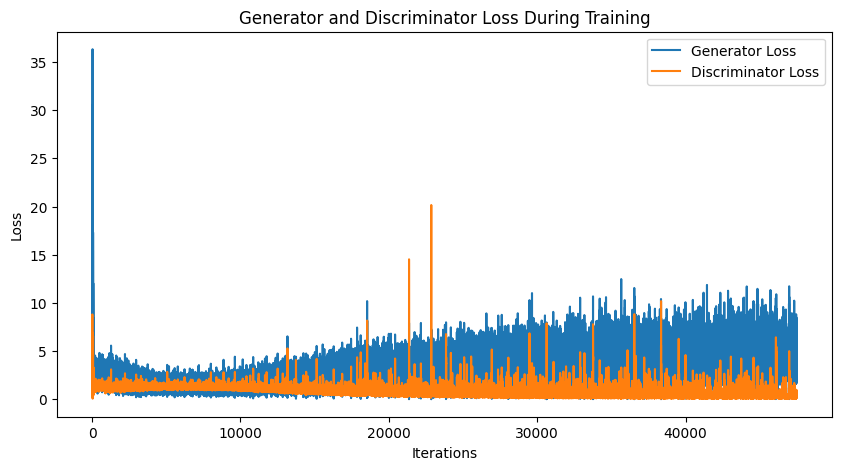

In [12]:
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()


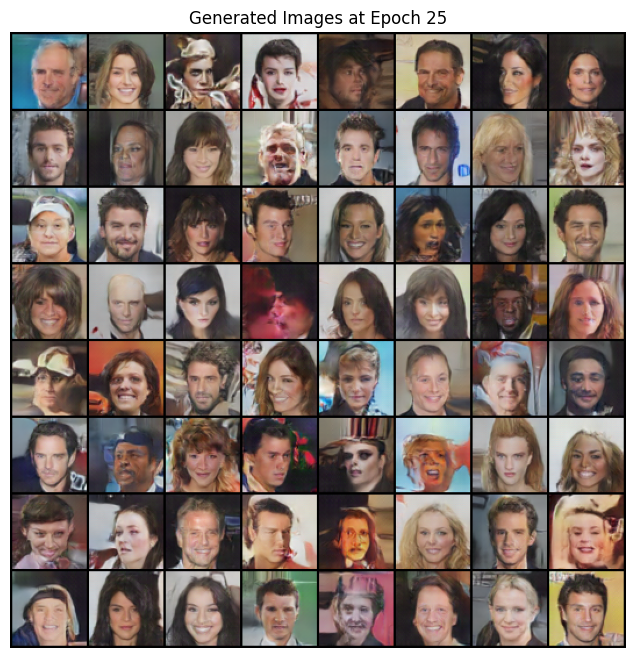

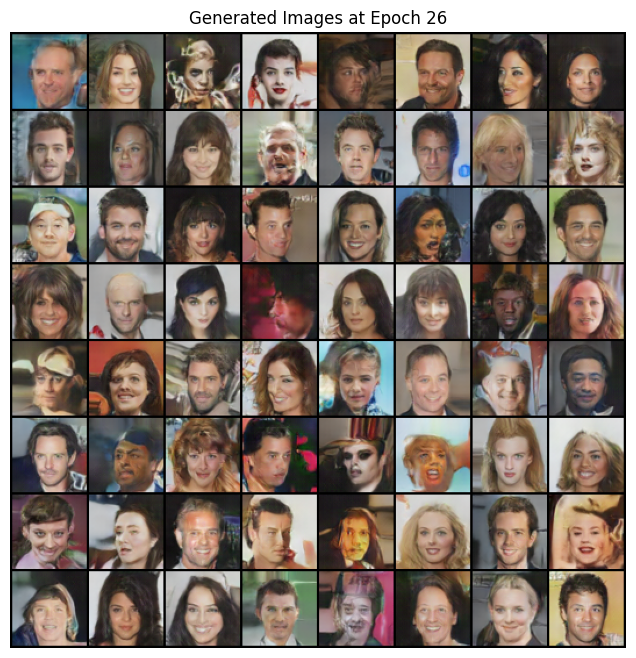

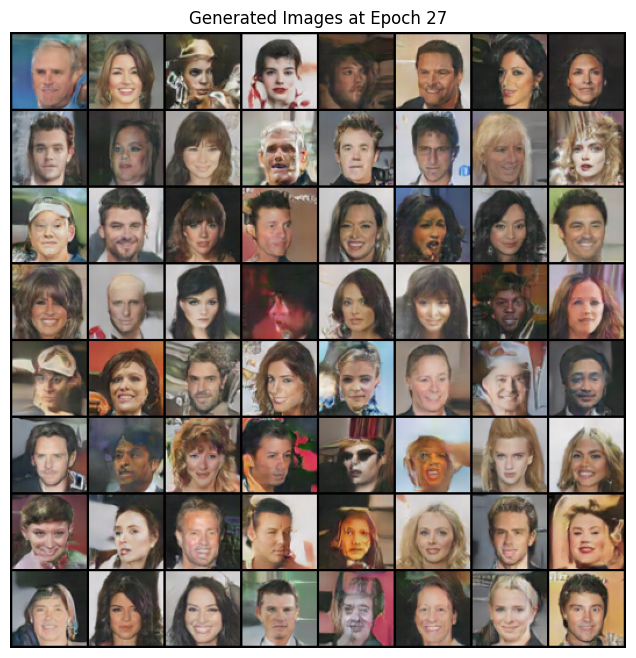

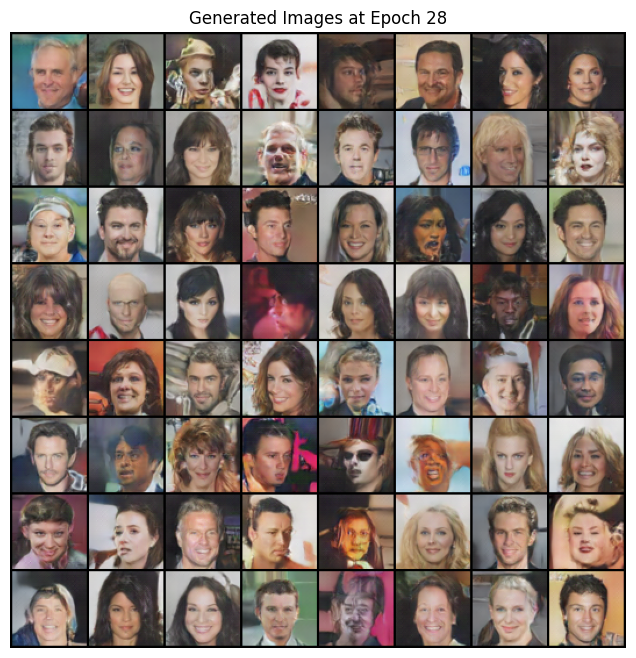

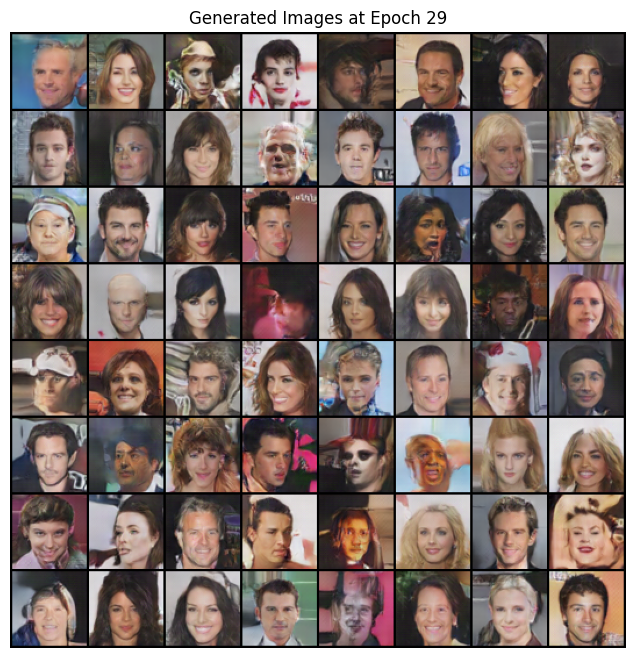

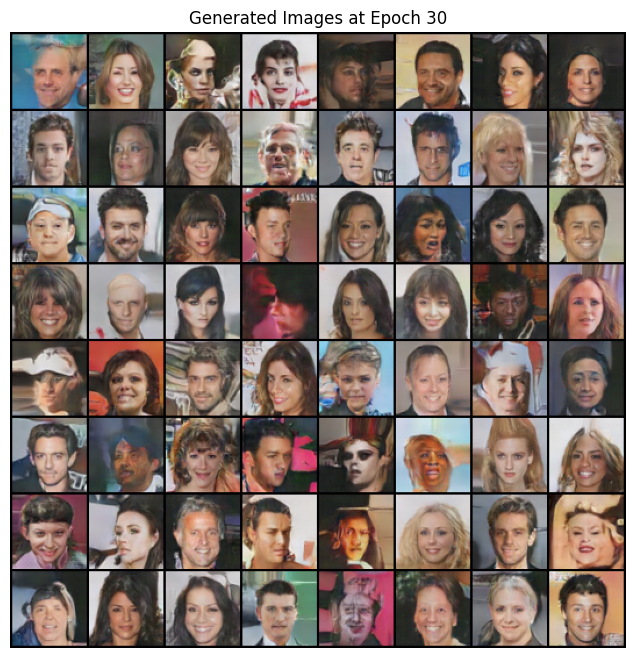

In [13]:
# Function to display images
def show_generated_images(epoch):
    img = plt.imread(f'/content/generated_images/epoch_{epoch}.png')
    plt.figure(figsize=(8,8))
    plt.axis("off")
    plt.title(f"Generated Images at Epoch {epoch}")
    plt.imshow(img)
    plt.show()

# Display images from the last few epochs
for epoch in range(num_epochs-5, num_epochs+1):
    show_generated_images(epoch)
